## Reinforcement-learning practical - Neurograd26 - Part 1

The goal of this first part is to learn how to simulate the behavior of various agents in a reinforcement learning task.

It includes exercises. At the end of this first part you'll have to send this notebook to `romain.ligneul@inserm.fr`.

To keep track of submissions, write your name(s) in the cell below

In [ ]:
"""Write your names here:



"""

'Write your names here:\n\n\n\n'

#### Activate your conda environment

Type
`conda activate neurograd`

Then `pip install` the modules below
joblib
tqdm


In [ ]:
# Import modules
import numpy as np
import random
import pandas as pd
import seaborn as sns
from joblib import Parallel, delayed
import matplotlib.pyplot as plt

## Make an environment to simulate the task

Any behavioral modeling project needs a "simulator", that is, a piece of code that can be used to simulate all relevant aspects of an experiment, including the interaction of an agent with it.

#### Task builder
We start by defining a function named `buildRLWMtask` that will return a dictionary containing all the information needed to run a simulation
- some general properties
- a list of blocks
- a list of trials for each block

#### Task runner
Then, we define a function named `runRLWMtask` that will iterate over blocks and trials and determine when an "agent" function (wait for the next section) should act and update its hidden states.

In [ ]:
### Task builder
# This function will be called each time we want to BUILD a new simulation

def buildRLWMtask():
  # nrepeats: indicates the number of repetition, within each block, for each stimulus in the set
  # toleranceAvgDistanceRepetition: enforces a constrain on the distance (in trials) between two repetitions of a given stimulus
  # blocklist: list that specifies the blocks that will be encountered (will be shuffled)
  # blocklist["setSize"]: indicates the number of different stimuli in the block
  # blocklist["correctAction"]: indicates the correct action for each stimulus in the set (will be shuffled)

  # Build properties of the task
  expdef={
    "nrepeats":12,
    "toleranceAvgDistanceRepetition":0.25,
    "feedbackValues": [2,3],
    "blocklist":[
        {"setSize": 2,"correctAction": [0,1], 'nActions': 3},
        {"setSize": 2,"correctAction": [1,2], 'nActions': 3},
        {"setSize": 3,"correctAction": [0,1,2], 'nActions': 3},
        {"setSize": 3,"correctAction": [1,1,2], 'nActions': 3},
        {"setSize": 3,"correctAction": [0,0,2], 'nActions': 3},
        {"setSize": 4,"correctAction": [0,1,2,2], 'nActions': 3},   
        {"setSize": 4,"correctAction": [0,1,1,2], 'nActions': 3},    
        {"setSize": 4,"correctAction": [0,0,1,2], 'nActions': 3},
        {"setSize": 5,"correctAction": [0,0,1,2,2], 'nActions': 3},    
        {"setSize": 5,"correctAction": [0,1,1,2,2], 'nActions': 3},
        {"setSize": 5,"correctAction": [0,0,1,1,2], 'nActions': 3},
        {"setSize": 6,"correctAction": [0,0,1,1,2,2], 'nActions': 3},    
        {"setSize": 6,"correctAction": [0,0,1,1,2,2], 'nActions': 3}
    ]
  }

  # Randomize block ordering
  random.shuffle(expdef["blocklist"])
  
  # Initialize our global trial index
  gTidx=0 

  # Loop over blocks to add blocklist (list of lists of trials)
  for blockidx, blockInfo in enumerate(expdef["blocklist"]):
    
    # Randomize Stimulus-Action mapping
    random.shuffle(blockInfo["correctAction"])
    
    # Shuffle the order of stimuli until the spacing condition is met 
    stimlist = []
    for stimidx in range(blockInfo["setSize"]):
      stimlist.extend([stimidx] * expdef['nrepeats'])
    spacing_condition=False
    
    while not spacing_condition:

        # Shuffle the stim indices
        random.shuffle(stimlist)
        last_seen = {}
        gaps = {}
        # Compute the length of gaps between repetition of the same image
        for i, stimidx in enumerate(stimlist):
            if stimidx in last_seen:
                gap = i - last_seen[stimidx]
                if stimidx not in gaps:
                    gaps[stimidx] = []
                gaps[stimidx].append(gap)
            last_seen[stimidx] = i
        # Assert whether the spacing condition is met (if so, the while loop will break)
        spacing_condition = all(
            (sum(gap_list) / len(gap_list)) >= (blockInfo['setSize'] - expdef['toleranceAvgDistanceRepetition']) and
            (sum(gap_list) / len(gap_list)) <= (blockInfo['setSize'] + expdef['toleranceAvgDistanceRepetition'])
            for gap_list in gaps.values()
        )
  
    # Build trial array based on the valid pseudorandomized stim sequence
    block_trials=[]
    repeats_counter=np.zeros((blockInfo['setSize'],))
    for tblock_num, stimidx in enumerate(stimlist):
      # assign trial info
      trial = {
          'correctAction': blockInfo['correctAction'][stimidx],
          'correctFeedback': expdef['feedbackValues'][stimidx % 2],
          'setSize': blockInfo['setSize'],
          'stimIdx': stimidx,
          'blockIdx': blockidx,
          'btrialIdx': tblock_num,
          'gTidx': gTidx,
          'repeatIdx': repeats_counter[stimidx],
          'nActions': blockInfo['nActions'],
      }

      repeats_counter[stimidx]+=1
      # increment experiment-wise trial number
      gTidx+=1
      # append trial to the list
      block_trials.append(trial)   
    
    # add triallist to the current blocklist
    expdef['blocklist'][blockidx]['triallist']=block_trials
    
  return expdef

### Sanity check
# Have a look at the first trials of the last block of an instance of the RLWM task to check that everything is alright
expdef=buildRLWMtask()
print(expdef['blocklist'][-1]['triallist'][:3])

[{'correctAction': 1, 'correctFeedback': 2, 'setSize': 3, 'stimIdx': 0, 'blockIdx': 12, 'btrialIdx': 0, 'gTidx': 588, 'repeatIdx': np.float64(0.0), 'nActions': 3}, {'correctAction': 1, 'correctFeedback': 2, 'setSize': 3, 'stimIdx': 2, 'blockIdx': 12, 'btrialIdx': 1, 'gTidx': 589, 'repeatIdx': np.float64(0.0), 'nActions': 3}, {'correctAction': 2, 'correctFeedback': 3, 'setSize': 3, 'stimIdx': 1, 'blockIdx': 12, 'btrialIdx': 2, 'gTidx': 590, 'repeatIdx': np.float64(0.0), 'nActions': 3}]


In [ ]:
### Task runner
# This function will be called each time we want to RUN a new simulation

def runRLWMtask(parameters, expdef=None,agent=None,memory=False,realdata=None):

  # Initialize the negative log-likelihood term
  NLL=0
  
  # Initialize df_memory if required
  if memory:
    df_memory=pd.DataFrame()
  
  # Initialize global trial index
  gTidx=0

  # Loop over blocks
  for bidx, block in enumerate(expdef['blocklist']):
    
    # Initialize agent (to reset hidden states for this block)
    context=block['triallist'][0]
    context, hsX,info=agent(parameters,context=context, mode='init')
    
    # if memory, build column names for hidden states
    if memory and 'hs_map' in info:
      hs_columns=[]
      for key, item in info['hs_map'].items():
        rows, cols = item.shape
        # Prepare the list
        for r, c in np.ndindex(rows, cols):
            idx = item[r, c]            # the integer inside the array
            hs_columns.append(f"{key}({r},{c})")
    
    # Loop over list of trials
    for trial in block['triallist']:
      
      # Context for this trial
      context=trial
      
      # Act
      if realdata is None:
        context, hsX,info=agent(parameters,context=context,hsX=hsX, info=info, mode='act')
      else:
        context['action']=realdata['action'].values[gTidx]
        context, hsX,info=agent(parameters,context=context,hsX=hsX, info=info, mode='get_likelihood')
      
      # Increment NLL
      NLL+=-np.log(context['likelihood'])
      
      # Give reward if action is correct, omit otherwise
      if realdata is None:
        if context['action']==trial['correctAction']:
          context['reward']=trial['correctFeedback']
          context['accuracy']=1
        else:
          context['reward']=0
          context['accuracy']=0
      else:
        if context['action']==trial['correctAction']:
          context['accuracy']=1
        else:
          context['accuracy']=0
        context['reward']=realdata['reward'].values[gTidx]
      
      # Log everything into df_memory before updating
      if memory:
        df_context=pd.DataFrame([context],index=[0])
        if 'hs_map' in info:
          df_hs=pd.DataFrame([hsX],index=[0],columns=hs_columns)
          df_context=pd.concat([df_context,df_hs],axis=1).reset_index(drop=True)
        df_memory=pd.concat([df_memory,df_context],axis=0,ignore_index=True).reset_index(drop=True)
        
      # Update hidden states
      context, hsX,info=agent(parameters,context=context,hsX=hsX, info=info, mode='update')

  # Return 
  if memory:
    return NLL, info, df_memory
  else:
    return NLL

## Define our first RL agent

Any behavioral modeling project needs a "agent", that is, a piece of code that defines:
- an initial state
- an observation or policy function (i.e. a mechanism that selects actions in response to changes in the environment)
- an update or evolution function (i.e. a mechanism that update hidden states in response to changes in the environment)

In this notebook, we'll code a simple "RLAgent" and then you'll work on a slightly more elaborate one named "ForgettingRLAgent"

#### The agent function

Our "agents" are always defined by a function that accepts the following input:
- **parameters**: a 1D numpy array containing the (free) parameters that will be used to learn, decide, etc.
- **hsX**: a 1D numpy array containing the values of the hidden states (e.g. learned values) used by this model
- **context**: a dictionary that contains various information about the current trial (e.g. the stimulus in "stimIdx", the action in "action", etc)
- **info**: a dictionary that contains various information about the model: it is mostly a "helper" variable
- **mode**: a string that determines what the function will do when called.

The **mode** argument can have the following values
1. mode=="init": 
  - Initialize hidden states (e.g. learned stimulus-action RL values) as a 1D numpy array (hsX)
  - Construct the versatile `info` dictionary which allows amongst other things to to know what is what in hsX.
    For example info['hs_map']['RLval'][1,2] gives use the linear indice in hsX corresponding to the learned value of action=2 when stimIdx=1
    `info` also include the number of free parameters, the number of hidden states, and a p_map that tells us what is what in the input array `parameters`
2. mode=="act":
  - Select an action using a decision rule (here, a simple softmax rule), some parameters (e.g. a `beta` or inverse temperature) and relevant values in hsX
  - Compute the likelihood of this action knowing the model and the parameters
  mode=="get_likelihood" is almost the same as act, except that it does not select an action, instead it uses an action already defined in runRLWMtask (useful to fit data)
3. mode=="update":
  - Update hidden states based on task events
  For now, it just updates the RL value of the stimulus/action pair according to the reward delivered and a learning rate (`alpha`)

#### Simulation loop

We will use parallel computing (joblib) to simulate faster using all the CPUs available on the machine.
This is why we define a `simulation_wrapper` that implements the few steps needed for each unique simulation (build a task, get parameters, run the simulation, log some stuff)

#### Note: we'll simulate and fit using the same functions
In general, it is a **very good idea** to simulate surrogate data and fit real data using the same set of functions. This greatly reduces redundancies and ensures alignment between your simulations and your fits.
This is why the `runRLWMtask` has an argument named `realdata` that is not used so far and why our agent functions have a "get_likelihood" mode that skips the line of code that simulates choices (when fitting realdata, we instead use the actual choices of our participants)
However, in this notebook, we only simulate things!

In [ ]:
### Define our first agent

def RLAgent(parameters, hsX=None, context={},info={}, mode='act', fixed_parameters={}):
  
  ######### INIT #########
  if mode=='init':
    hsX=np.empty((0,))
    n_hs=0
    hs_map={}
    # RL values (one per stimulus/action pair)
    n_SApairs=context['setSize']*context['nActions']
    # Init all RL values to 1
    RLval0=np.zeros((n_SApairs,))
    # Add RL values to the hidden state map (hs_map)
    hs_map['RLval']=n_hs+np.arange(n_SApairs).reshape(context['setSize'], context['nActions'])
    n_hs=n_hs+RLval0.shape[0]
    # concatenate with linear 1D hidden state vector
    hsX=np.concatenate((hsX,RLval0))
    # create info structure
    info={
      'hs_map': hs_map,
      'hs_init': {
        'RLval': RLval0
      },
      'n_hs': n_hs,
      'p_map': {
        'alphaRL': 0,
        'betaRL': 1,
      },
      'bounds': {
        'alphaRL':[0.0001,1.0],
        'betaRL':[-10.0,100.0],
      },
      'plausible_bounds':{
        'alphaRL':[0.05,0.95],
        'betaRL':[0.0,50.0],
      }
    }
    info['n_p']=len(info['p_map'])

  ######### ACT ##########
  # mode=='act' means that an action will be chosen amongst alternatives
  # mode=='get_likelihood' means that we use a predefined action (usually, from real choice data)
  elif mode=='act' or mode=='get_likelihood':
    # select option based on learned RL values
    logits=np.empty((context['nActions'],))
    for actidx in range(context['nActions']):
      RLvalidx=info['hs_map']['RLval'][context['stimIdx'],actidx]
      logits[actidx]=parameters[info['p_map']['betaRL']]*hsX[RLvalidx]
    # basic softmax
    actProbs=np.exp(logits) / np.sum(np.exp(logits))
    # chose something if needed (act mode for simulation)
    if mode=='act':
      context['action']=np.random.choice(np.arange(context['nActions']), p=actProbs)
    # compute likelihood
    context['likelihood']=actProbs[context['action']]
    
  ######## UPDATE ########
  elif mode=='update':
    RLvalidx=info['hs_map']['RLval'][context['stimIdx'],context['action']]
    # compute reward prediction error
    RLPE=context['reward']-hsX[RLvalidx]
    # update corresponding hidden state using learning rate
    hsX[RLvalidx]+=parameters[info['p_map']['alphaRL']]*RLPE
  
  ######## RETURN ########
  # in any case, return context and hsX
  context['mode']=mode
  #
  return context, hsX, info

In [ ]:
#### Wrapper function (for parallel computing)

def simulation_wrapper(simidx,Agent,list_parameters):
  
    # create an instance of the task
    expdef = buildRLWMtask()
  
    # simulation parameters
    sim_parameters=list_parameters[simidx]

    # simulate the task with parameters
    NLL, info, df_memory = runRLWMtask(
        sim_parameters,
        expdef=expdef,
        agent=Agent,
        memory=True
    )

    # log some info
    df_memory["simIdx"]  = simidx
    for key, pidx in info['p_map'].items():
      df_memory[key] = sim_parameters[pidx]
    df_memory["finalNLL"]  = NLL
    
    # return memory
    return df_memory

In [ ]:
### Simulate some surrogate data using our RLAgent

# Define the ground truth value of the parameters used for the simulation
# nb: all combination of values of be simulated and repeated a number of times
list_alphaRL=[0.01, 0.25, 1.0]
list_betaRL=[0.0, 2.5, 25.0]
repeat_combinations=5

# Create the list of parameters used for each simulation
list_parameters=[]
for r in range(repeat_combinations):
  for alpha in list_alphaRL:
    for beta in list_betaRL:
      list_parameters.append(np.array([alpha,beta]))

# How many simulations
nsims=len(list_parameters)
print(f"Starting {nsims} simulations")

# Run the simulation loop
results = Parallel(n_jobs=-1, backend="loky")(
    delayed(simulation_wrapper)(simidx, RLAgent,list_parameters)
    for simidx in range(nsims)
)

# Concatenate all results into a single dataframe
df_memories = pd.concat(results, ignore_index=True)

Starting 45 simulations


Text(0.5, 1.0, 'Accuracy x Repetition x Set size')

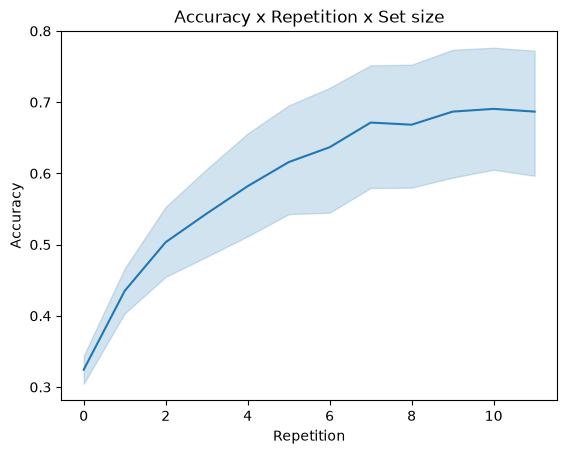

In [ ]:
### Check the accuracy of our simulated agents using seaborn

#  Average data of blocks that have the same set size
df_plot=df_memories.groupby(by=['simIdx','repeatIdx']).mean(numeric_only=True).reset_index()

# Rename columns for nicer axis labels
df_plot=df_plot.rename(columns={'repeatIdx': 'Repetition', 'setSize': 'Set size', 'accuracy': 'Accuracy'})

# Plot and give a title
g=sns.lineplot(df_plot, y='Accuracy', x='Repetition')
g.set_title("Accuracy x Repetition x Set size")


## EXERCISES

Now you will perform a few exercises that should consolidate what we've just seen.


### EXERCISE 1: do more with seaborn

Seaborn is a really useful package to visualize data contained in pandas data frames. We'll start by plotting a few more things using df_memories.

Its documentation is good:
https://seaborn.pydata.org/api.html

#### EXERCISE 1.1
In the next cell, use the seaborn function "relplot" to plot the accuracy of the simulated subjects as a function of repetition (x axis), alphaRL (hue) and betaRL (subplot column).
Unless you want to, no need to give you figure a title (it is a bit trickier when using `relplot` as compared to simpler methods like `lineplot`).

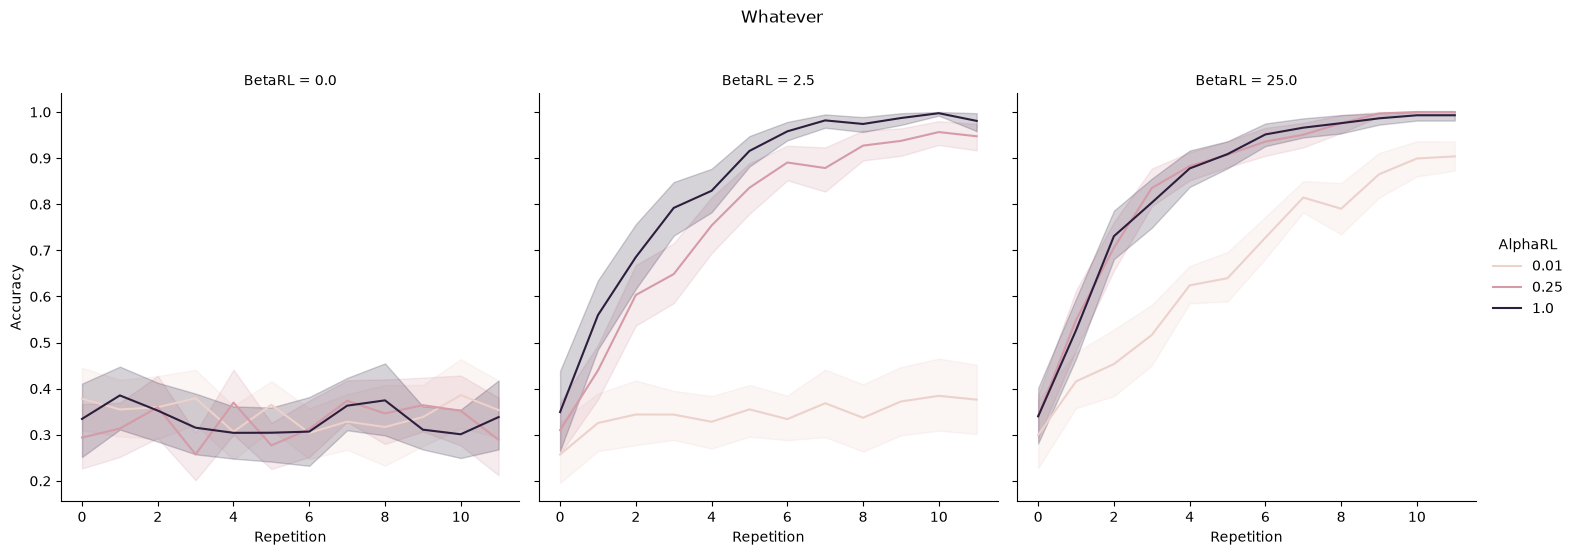

In [ ]:
### EXERCISE 1.1

#  Average data of blocks that have the same set size
df_plot=df_memories.groupby(by=['simIdx','setSize', 'repeatIdx']).mean(numeric_only=True).reset_index()

# Rename columns for nicer axis labels
df_plot=df_plot.rename(columns={'repeatIdx': 'Repetition', 'setSize': 'Set size', 'accuracy': 'Accuracy', 'alphaRL': 'AlphaRL', 'betaRL': 'BetaRL'})

# Plot
# ...
g=sns.relplot(df_plot, hue='AlphaRL', y='Accuracy', x='Repetition', col='BetaRL',kind='line')
g.fig.suptitle("Whatever", y=1.1)
g.fig.savefig("init0.png")

#### EXERCISE 1.2
In the next cell, describe concisely the plot generated in the previous cell (2-3 lines max). 
Why do you think some combinations of parameters lead to nearly perfect performance after only 2 repetitions?

In [ ]:
"""
Write your answer here




"""

'\nWrite your answer here\n\n\n\n\n'

### EXERCISE 2: code a variant of RLAgent

In this exercise, you'll have to modify an agent function (ForgettingRLAgent) in order to make it forget continuously the RL values it is learning during the task.
Implement this forgetting process as described in the Methods sections of Collins et al. (2017). The PDF of this article is in the `resources` folder.
Then, you'll use this variant to run new simulations!

#### EXERCISE 2.1

For now, the function ForgettingRLAgent in the next cell is simply a copy paste of our initial RLAgent. 

You'll need to change a few things in it, so that it uses a **third** free parameter named *decayRL* that controls how fast, **all** learned RL values return to their **initial** values (as provided by info['hs_init]['RLval']).

Forgetting can take place just before or just after updating.

In [ ]:
### ForgettingRLAgent to modify

def ForgettingRLAgent(parameters, hsX=None, context={},info={}, mode='act', fixed_parameters={}):
  
  ######### INIT #########
  if mode=='init':
    hsX=np.empty((0,))
    n_hs=0
    hs_map={}
    # RL values (one per stimulus/action pair)
    n_SApairs=context['setSize']*context['nActions']
    # Init all RL values to 1
    RLval0=np.ones((n_SApairs,))
    # Add RL values to the hidden state map (hs_map)
    hs_map['RLval']=n_hs+np.arange(n_SApairs).reshape(context['setSize'], context['nActions'])
    n_hs=n_hs+RLval0.shape[0]
    # concatenate with linear 1D hidden state vector
    hsX=np.concatenate((hsX,RLval0))
    # create info structure
    info={
      'hs_map': hs_map,
      'hs_init': {
        'RLval': RLval0
      },
      'n_hs': n_hs,
      'p_map': {
        'alphaRL': 0,
        'betaRL': 1,
        'decayRL': 2
      },
    }
    info['n_p']=len(info['p_map'])


  ######### ACT ##########
  # mode=='act' means that an action will be chosen amongst alternatives
  # mode=='get_likelihood' means that we use a predefined action (usually, from real choice data)
  elif mode=='act' or mode=='get_likelihood':
    # select option based on learned RL values
    logits=np.empty((context['nActions'],))
    for actidx in range(context['nActions']):
      RLvalidx=info['hs_map']['RLval'][context['stimIdx'],actidx]
      logits[actidx]=parameters[info['p_map']['betaRL']]*hsX[RLvalidx]
    # basic softmax
    actProbs=np.exp(logits) / np.sum(np.exp(logits))
    # chose something if needed (act mode for simulation)
    if mode=='act':
      context['action']=np.random.choice(np.arange(context['nActions']), p=actProbs)
    # compute likelihood
    context['likelihood']=actProbs[context['action']]
    
  ######## UPDATE ########
  elif mode=='update':
    allRLidx=info['hs_map']['RLval'].flatten()
    decayRL=parameters[info['p_map']['decayRL']]
    hsX[allRLidx]=hsX[allRLidx]+decayRL*(info['hs_init']['RLval']-hsX[allRLidx])
    RLvalidx=info['hs_map']['RLval'][context['stimIdx'],context['action']]
    # compute reward prediction error
    RLPE=context['reward']-hsX[RLvalidx]
    # update corresponding hidden state using learning rate
    hsX[RLvalidx]+=parameters[info['p_map']['alphaRL']]*RLPE
  
  ######## RETURN ########
  # in any case, return context and hsX
  context['mode']=mode
  #
  return context, hsX, info


#### EXERCISE 2.2

Now, we want to simulate subject using ForgettingRLAgent in order to assess the impact of different values of the decayRL parameter

In the next cell, you'll find a copy-past of the code we've used earlier. You'll need to modify it in order to:
1. Test the effect of different decayRL: [0.0, 0.05, 0.1]
3. Use only a single learning rate: alphaRL should be 0.2 in all simulations
3. Use only a single inverse temperature: betaRL should be 5 in all simulations

4. Use 20 `repeat_combinations`

In [ ]:
### EXERCISE 2.2: code to modify

# Define the ground truth value of the parameters used for the simulation
# nb: all combination of values of be simulated and repeated a number of times
unique_alphaRL=0.2
unique_betaRL=5.0
list_decayRL=[0.0,0.05,0.1]
repeat_combinations=20

# Create the list of parameters used for each simulation
list_parameters=[]
for r in range(repeat_combinations):
  for decay in list_decayRL:
    list_parameters.append(np.array([unique_alphaRL,unique_betaRL,decay]))

# How many simulations
nsims=len(list_parameters)
print(f"Starting {nsims} simulations")

# Run the simulation loop
results = Parallel(n_jobs=-1, backend="loky")(
    delayed(simulation_wrapper)(simidx, ForgettingRLAgent,list_parameters)
    for simidx in range(nsims)
)

# Concatenate all results into a single dataframe
df_memories = pd.concat(results, ignore_index=True)

Starting 60 simulations


#### EXERCISE 2.3

Now, modify the following cell to plot the accuracy of simulated agents as a function of repetitions, setSize (hue), and decayRL (subplot column)

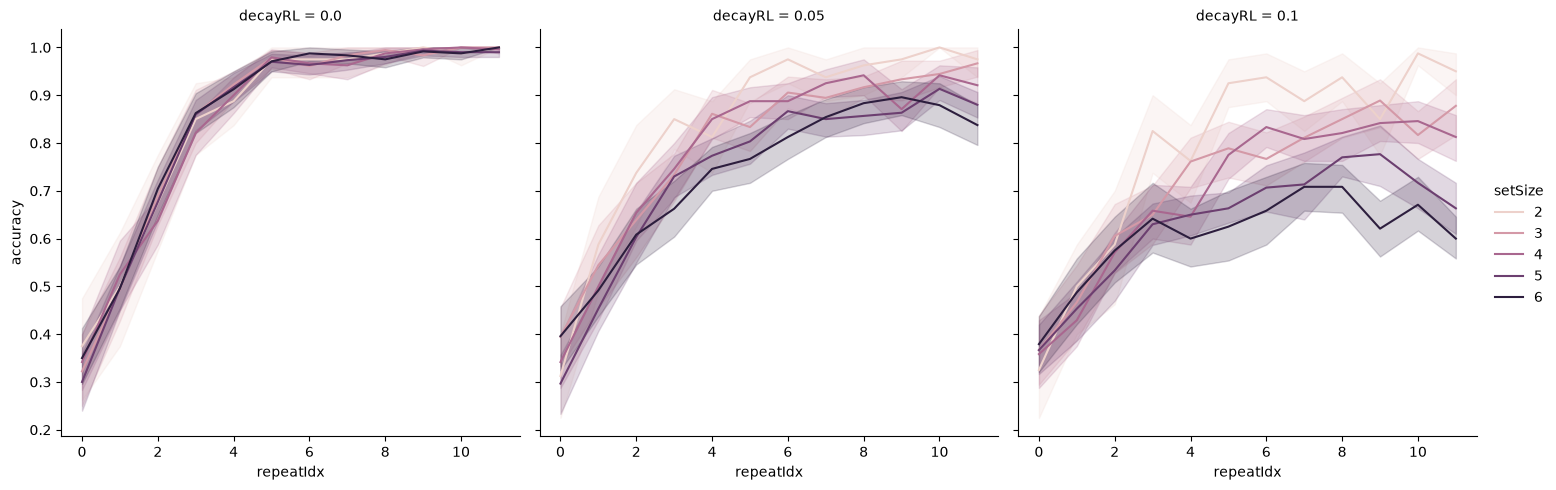

In [ ]:
### EXERCISE 2.3

#  Average data of blocks that have the same set size
df_plot=df_memories.groupby(by=['simIdx','setSize', 'repeatIdx']).mean(numeric_only=True).reset_index()
df_plot['decayRL']=df_plot['decayRL'].round(3)

# Rename columns for nicer axis labels
# ...

# Plot
g=sns.relplot(df_plot,hue="setSize",x="repeatIdx",y="accuracy",col="decayRL", kind="line")

#### EXERCISE 2.4

In the next cell, describe what you see on the plot that you just generated.

There is something *qualitatively* different as compared to previous simulations. What?

In [ ]:
"""
Write your answer here




"""

'\nWrite your answer here\n\n\n\n\n'

### EXERCISE 3: dealing with problems

In real life, using computational models often requires to **debug** your code, that is, understand where errors are coming from and correct them.

One of the most common types of problems that does not come from basic coding mistakes are "numerical problems".

The agent function below is an exact copy of our initial RLAgent. It is used by the following cell to simulate data using a very high inverse temperature (5000). But executing this cell will give you an error!

You goal in this last exercise of Part 1 will be to modify `DebugRLAgent` so that the following cell (starting with `### EXERCISE 3: Simulation with DebugRLAgent`) runs **without any error**!

You cannot change the value of betaRL (i.e. sim_parameters)!

But you may use the help of you favorite LLM :)

In [ ]:
### EXERCISE 3: function to modify

def DebugRLAgent(parameters, hsX=None, context={},info={}, mode='act', fixed_parameters={} ):
  
  ######### INIT #########
  if mode=='init':
    hsX=np.empty((0,))
    n_hs=0
    hs_map={}
    # RL values (one per stimulus/action pair)
    n_SApairs=context['setSize']*context['nActions']
    # Init all RL values to 1
    RLval0=np.ones((n_SApairs,))
    # Add RL values to the hidden state map (hs_map)
    hs_map['RLval']=n_hs+np.arange(n_SApairs).reshape(context['setSize'], context['nActions'])
    n_hs=n_hs+RLval0.shape[0]
    # concatenate with linear 1D hidden state vector
    hsX=np.concatenate((hsX,RLval0))
    # create info structure
    info={
      'hs_map': hs_map,
      'hs_init': {
        'RLval': RLval0
      },
      'n_hs': n_hs,
      'p_map': {
        'alphaRL': 0,
        'betaRL': 1,
      },
      'bounds': {
        'alphaRL':[0.0001,1.0],
        'betaRL':[-10.0,100.0],
      },
      'plausible_bounds':{
        'alphaRL':[0.05,0.95],
        'betaRL':[0.0,50.0],
      }
    }
    info['n_p']=len(info['p_map'])

  ######### ACT ##########
  # mode=='act' means that an action will be chosen amongst alternatives
  # mode=='get_likelihood' means that we use a predefined action (usually, from real choice data)
  elif mode=='act' or mode=='get_likelihood':
    # select option based on learned RL values
    logits=np.empty((context['nActions'],))
    for actidx in range(context['nActions']):
      RLvalidx=info['hs_map']['RLval'][context['stimIdx'],actidx]
      logits[actidx]=parameters[info['p_map']['betaRL']]*hsX[RLvalidx]
    # 
    print('logits: ', logits)
    banana
    logits-=np.max(logits)
    # basic softmax
    actProbs=np.exp(logits) / np.sum(np.exp(logits))
    # chose something if needed (act mode for simulation)
    if mode=='act':
      context['action']=np.random.choice(np.arange(context['nActions']), p=actProbs)
    # compute likelihood
    context['likelihood']=actProbs[context['action']]
    
  ######## UPDATE ########
  elif mode=='update':
    RLvalidx=info['hs_map']['RLval'][context['stimIdx'],context['action']]
    # compute reward prediction error
    RLPE=context['reward']-hsX[RLvalidx]
    if 'counterfactual' in fixed_parameters:

    # update corresponding hidden state using learning rate
    hsX[RLvalidx]+=parameters[info['p_map']['alphaRL']]*RLPE
  
  ######## RETURN ########
  # in any case, return context and hsX
  context['mode']=mode
  #
  return context, hsX, info

IndentationError: expected an indented block after 'if' statement on line 65 (1616788985.py, line 68)

In [ ]:
np.exp(-1000000)

np.float64(0.0)

In [ ]:
### EXERCISE 3: Simulation with DebugRLAgent

# build an instance of the task
expdef = buildRLWMtask()

# use a learning rate of 0.1 and a very high beta
sim_parameters=np.array([0.1,5000.0])

# run the simulation
NLL, info, df_memory = runRLWMtask(
    sim_parameters,
    expdef=expdef,
    agent=DebugRLAgent,
    memory=True
)


C:\Users\Romain\AppData\Local\Temp\ipykernel_29596\3056894919.py:5: RuntimeWarning: overflow encountered in exp
  y=np.exp(x)


Text(0.5, 1.0, "What's happening here?")

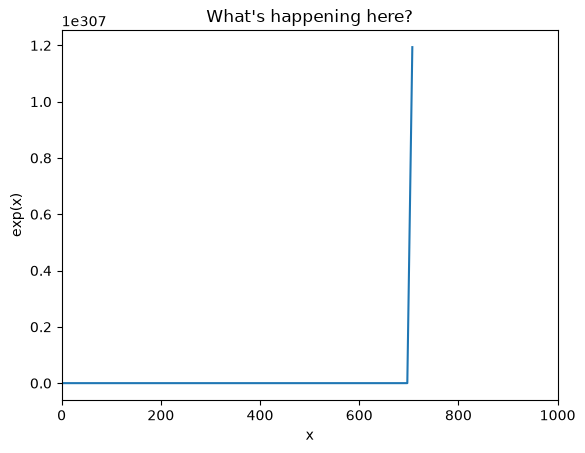

In [ ]:
# EXERCISE 3 (hint): Executing this cell and trying to understand it may give you a hint...
xmin=0
xmax=1000
x=np.linspace(xmin,xmax,100)
y=np.exp(x)
plt.plot(x,y)
plt.xlim(xmin,xmax)
plt.xlabel('x')
plt.ylabel('exp(x)')
plt.title("What's happening here?")

## EXERCISE 4: Create a RLWM agent

Now, you will try to create an agent which does not only learns RL values, but also WM values.
You can start from the first RLAgent defined above and:
- extend the hidden states used by the model to include WM values
- add at least a decayWM parameter and a WMweight parameter, both in the [0,1] range
- modify the "act" and "update" sections accordingly so as to 

Note that the WM module works exactly like an RL module, except that its learning rate is always 1! 

You can search for relevant papers by Anne Collins. There is also some Matlab code available on Github that shows how these models are written... 

Once you have written the agent function, you may run simulations and plot some results using the same type of code as we used above.